# Practical 3, Part II: Frank–Read Source Activation with microMegas

**Materials Simulation Practical 3, implementation tasks** · Ali Ghelichkhani ([ali.ghelichkhani@fau.de](mailto:ali.ghelichkhani@fau.de)) · Supervisor: Leon Pyka
Institute of Materials Simulation (WW8), FAU Erlangen-Nürnberg · Winter semester 2026/27

All simulations use the course repository [`LAPikachu/practical_DDD`](https://github.com/LAPikachu/practical_DDD),
cloned into `./practical_DDD` (git-ignored) and built with `make mm` in `dd/bin`. The theory —
DDD, the Peach–Koehler force, line tension and the Frank–Read critical stress — is in Part I
(`report/main.pdf`).

| Task | Content | Section |
|------|---------|---------|
| 1 | set-up, estimate and determination of $\tau_c$ for a 100 nm edge source, fit of $\alpha$ | [1](#1)–[3](#3) |
| 2 | $\tau_c$ vs. segment length 50–200 nm, comparison with theory, influence of parameters | [4](#4), [5](#5) |
| 3 | $\tau_c$ and $\alpha$ vs. character angle $\beta$ (edge → screw) | [6](#6) |

**Setup notes.** Two things had to be fixed to run the wrapper on macOS/arm64: the repository ships
Linux object files in `dd/bin/mm.objs`, which have to be deleted before `make mm`, and the output
directories `dd/out/{debug,vtk,SigInt_dir,GammaboxVTK}` must exist. Two bugs in
`micromegas_wrapper.py` are worked around in the driver below: `MicroMegasWrapper.run` passes the box
size as a tuple that the generator then tries to modify in place, and the generator writes the box size
as floats (`2464.0`), which the Fortran list-directed read rejects.

In [1]:
import subprocess, sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO = Path("practical_DDD").resolve()
sys.path.insert(0, str(REPO))
from micromegas_wrapper import MicroMegasWrapper, SimulationConfig   # course wrapper

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.autolayout": True})

for d in ("debug", "vtk", "SigInt_dir", "GammaboxVTK"):
    (REPO / "dd" / "out" / d).mkdir(parents=True, exist_ok=True)
assert (REPO / "dd" / "bin" / "mm").exists(), "build microMegas first: cd practical_DDD/dd/bin && make mm"

# material data of dd/in/Cu
MU = 42.0e3          # shear modulus [MPa]
NU = 0.431           # Poisson ratio used by microMegas for Cu
B = 0.25525          # Burgers vector [nm]
L_EDGE, L_SCREW = 5.9684, 3.4459     # elementary edge / screw vectors [nm]
print(f"mu b = {MU*B:.1f} MPa nm")

mu b = 10720.5 MPa nm


<a id="1"></a>
## 1 Driver and set-up (Task 1.1–1.5)

`SimulationConfig` sets the segment length, the character angle $\beta$ (angle between line and
Burgers vector), the box size and the start point; the nested `ContCuConfig` holds the 41 control
parameters of the `ContCu` file. The reference glide system of `dd/in/Cu` is
$(\bar1\bar1\bar1)[10\bar1]$, exactly the slip system the task asks for, so the generated segment lies
on that plane with that Burgers vector. With `shear = 'T'` the applied stress `sigma0` is the resolved
shear stress on the most highly stressed system: the run log prints `Tau = sigma0` and
`Sig = sigma0 / 0.408`, the Schmid factor of $\{111\}\langle110\rangle$ for a $[001]$ axis.

We run at **constant stress** (`mode_deformation = 4`). Below $\tau_c$ the source bows out to a stable
arc and stops; above it, the arc passes the semicircle, the source operates and keeps emitting loops,
so the number of segments and the plastic strain grow without bound. That gives a sharp, binary test.

In [2]:
WRAPPER = MicroMegasWrapper(str(REPO))


def run_mm(L_nm, beta, tau, nstep=4000, box_nm=3000, **cont):
    """One constant-stress microMegas run; returns rows (step, segments, strain %, tau)."""
    cfg = SimulationConfig(target_length_nm=L_nm, angle_deg=beta,
                           box_dim_x=box_nm, box_dim_y=box_nm, box_dim_z=box_nm)
    c = cfg.cont_cu
    c.mode_deformation, c.sigma0, c.nstep, c.kstats = 4, float(tau), nstep, 50
    for k, v in cont.items():
        setattr(c, k, v)
    nb = int(((box_nm / 1.2183) + 7) // 8 * 8)             # box in BVD units, as the generator does
    centre = nb // 2 // 8 * 8
    cfg.start_coord = (centre, centre, centre)

    tag = str(time.time_ns())
    ind = REPO / "dd" / "in"
    WRAPPER._write_contcu(ind / f"ContCu_{tag}", c)
    seg = ind / f"Seg_{tag}"
    WRAPPER.generator.generate_smart_configuration(beta, L_nm, cfg.start_coord, [box_nm] * 3, str(seg))
    lines = seg.read_text().splitlines()
    lines[2] = " ".join(str(int(float(v))) for v in lines[2].split())   # wrapper bug: floats
    seg.write_text("\n".join(lines) + "\n")
    WRAPPER._write_input_dd(ind / "input.dd", "Cu", f"ContCu_{tag}", f"Seg_{tag}")

    out = subprocess.run(["./mm"], cwd=REPO / "dd" / "bin", check=True,
                         capture_output=True, text=True).stdout
    (ind / f"ContCu_{tag}").unlink()
    seg.unlink()
    rows = []
    for line in out.splitlines():
        t = line.split()
        if len(t) == 12 and t[0].isdigit():
            rows.append((int(t[0]), int(t[1]), float(t[3]), float(t[5])))
    return np.array(rows)


def is_active(rows):
    """Source operates if the line multiplies far beyond its bowed-out discretization."""
    return rows[:, 1].max() > 3 * rows[0, 1] + 30


def tau_crit(L_nm, beta, lo=5.0, hi=800.0, rtol=0.01, **kw):
    """Critical resolved shear stress by bisection (geometric) on constant-stress runs."""
    while hi / lo - 1 > rtol:
        mid = np.sqrt(lo * hi)
        if is_active(run_mm(L_nm, beta, mid, **kw)):
            hi = mid
        else:
            lo = mid
    return np.sqrt(lo * hi)


def actual_geometry(L_nm, beta):
    """End-to-end length and character angle of the segment the generator really builds."""
    if beta in (0, 60, 90):
        unit = L_EDGE if beta == 90 else L_SCREW
        return round(L_nm / unit) * unit, float(beta)
    b_ = np.radians(beta)
    ne, ns = round(L_nm * np.sin(b_) / L_EDGE), round(L_nm * np.cos(b_) / L_SCREW)
    return np.hypot(ne * L_EDGE, ns * L_SCREW), np.degrees(np.arctan2(ne * L_EDGE, ns * L_SCREW))


L100, _ = actual_geometry(100, 90)
print(f"a 100 nm edge segment is built from {round(100/L_EDGE)} edge vectors: L = {L100:.2f} nm")

a 100 nm edge segment is built from 17 edge vectors: L = 101.46 nm


<a id="2"></a>
## 2 Estimate of the critical stress (Task 1.6)

Hirth & Lothe give for the equilibrium of an arc of radius $r$ under the stress $\tau$

$$b\tau = \frac{\mu b^2}{4\pi(1-\nu)\,r}\left\{\left[1-\frac{\nu}{2}\left(3-4\cos^2\beta\right)\right]
\ln\frac{L}{\rho} - 1 + \frac{\nu}{2}\right\},$$

and the critical configuration is the semicircle, $r = L/2$. With $\tau_c = \alpha\mu b/L$ this gives

$$\alpha(\beta) = \frac{1}{2\pi(1-\nu)}\left\{\left[1-\frac{\nu}{2}\left(3-4\cos^2\beta\right)\right]
\ln\frac{L}{\rho} - 1 + \frac{\nu}{2}\right\}.$$

In [3]:
def alpha_hirth(beta, L_nm, nu=NU, rho_nm=None, L_over_rho=None):
    log = np.log(L_over_rho) if L_over_rho is not None else np.log(L_nm / (rho_nm or B))
    c2 = np.cos(np.radians(beta)) ** 2
    return ((1 - nu / 2 * (3 - 4 * c2)) * log - 1 + nu / 2) / (2 * np.pi * (1 - nu))


def tau_hirth(beta, L_nm, **kw):
    return alpha_hirth(beta, L_nm, **kw) * MU * B / L_nm


print("script check (nu = 0.33, L = 1000 rho):  "
      f"alpha_edge = {alpha_hirth(90, 100, nu=0.33, L_over_rho=1000):.2f}, "
      f"alpha_screw = {alpha_hirth(0, 100, nu=0.33, L_over_rho=1000):.2f}   (script: 0.5 and 1.5)")
print(f"\nestimate for the 100 nm edge source (mM values mu = 42 GPa, nu = {NU}):")
for lab, kw in [("rho = b", dict(rho_nm=B)), ("L = 1000 rho", dict(L_over_rho=1000))]:
    print(f"  {lab:13s}: alpha = {alpha_hirth(90, L100, **kw):.3f}, "
          f"tau_c = {tau_hirth(90, L100, **kw):.1f} MPa")
print(f"  with nu = 0.33 (rho = b): tau_c = {tau_hirth(90, L100, nu=0.33, rho_nm=B):.1f} MPa")

script check (nu = 0.33, L = 1000 rho):  alpha_edge = 0.63, alpha_screw = 1.71   (script: 0.5 and 1.5)

estimate for the 100 nm edge source (mM values mu = 42 GPa, nu = 0.431):
  rho = b      : alpha = 0.372, tau_c = 39.3 MPa
  L = 1000 rho : alpha = 0.464, tau_c = 49.0 MPa
  with nu = 0.33 (rho = b): tau_c = 54.9 MPa


<a id="3"></a>
## 3 Determination of $\tau_c$ and $\alpha$ (Task 1.7, 1.8)

First a look at the two regimes, then the bisection.

✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°


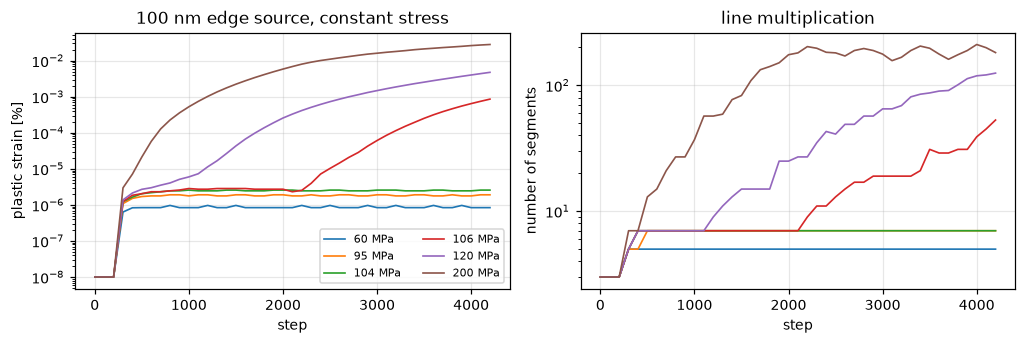

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9.4, 3.2))
for tau in (60, 95, 104, 106, 120, 200):
    r = run_mm(100, 90, tau)
    ax[0].semilogy(r[:, 0], np.maximum(r[:, 2], 1e-8), lw=1.1, label=f"{tau} MPa")
    ax[1].plot(r[:, 0], r[:, 1], lw=1.1, label=f"{tau} MPa")
ax[0].set(xlabel="step", ylabel="plastic strain [%]", title="100 nm edge source, constant stress")
ax[1].set(xlabel="step", ylabel="number of segments", yscale="log", title="line multiplication")
ax[0].legend(fontsize=7, ncol=2)
plt.show()

In [5]:
t0 = time.time()
TAU_C_100 = tau_crit(100, 90)
ALPHA_100 = TAU_C_100 * L100 / (MU * B)
print(f"tau_c (L = {L100:.1f} nm, edge) = {TAU_C_100:.1f} MPa   ({time.time()-t0:.0f} s)")
print(f"alpha = tau_c L / (mu b) = {ALPHA_100:.3f}")
print(f"Hirth estimate (rho = b): alpha = {alpha_hirth(90, L100):.3f}, "
      f"tau_c = {tau_hirth(90, L100):.1f} MPa -> ratio sim/theory = {TAU_C_100/tau_hirth(90, L100):.2f}")

# robustness of the result
checks = {
    "reference (DeWit line tension, 4000 steps, box 3 um)": {},
    "12000 steps": dict(nstep=12000),
    "box 1.5 um": dict(box_nm=1500),
    "box 6 um": dict(box_nm=6000),
    "re-discretization at 0.1 um": dict(ldis_act=0.1, ldis_nact=0.1),
    "Friedel line tension (linten = 0)": dict(linten=0),
    "Foreman line tension (linten = 2)": dict(linten=2),
}
robust = {}
for name, kw in checks.items():
    robust[name] = tau_crit(100, 90, **kw)
    print(f"  {name:55s} tau_c = {robust[name]:6.1f} MPa, alpha = {robust[name]*L100/(MU*B):.3f}")

✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


tau_c (L = 101.5 nm, edge) = 104.3 MPa   (2 s)
alpha = tau_c L / (mu b) = 0.987
Hirth estimate (rho = b): alpha = 0.372, tau_c = 39.3 MPa -> ratio sim/theory = 2.65
✅ Generated Native: 90°
✅ Generated Native: 90°


... (35 outputs left out)

✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


  Foreman line tension (linten = 2)                       tau_c =  100.3 MPa, alpha = 0.949


**Result of Task 1.** The 100 nm edge source in Cu operates at $\tau_c \approx 105$ MPa, i.e.
$\alpha \approx 1.0$. This is about twice the Hirth estimate with $\rho = b$. The checks show where the
difference comes from: the number of steps, the box size (a single source in a 3 µm box does not feel
its periodic images) and the re-discretization length change $\tau_c$ by less than 1 %, but the
**line-tension model** changes it by a factor of two. With Friedel's constant line tension
$T = \mu b^2/2$ the source operates at about 47 MPa ($\alpha \approx 0.45$), close to the analytic
estimate; with the default DeWit–Koehler form, which makes the line tension depend on character and
on a logarithm of the arc size, it needs about 105 MPa. In DDD the critical stress of a source is
controlled almost entirely by how the self-interaction of the curved line is treated.

<a id="4"></a>
## 4 Critical stress vs. segment length (Task 2)

In [6]:
LENGTHS = [50, 75, 100, 125, 150, 175, 200]
res_L = []
for L in LENGTHS:
    La, _ = actual_geometry(L, 90)
    tc = tau_crit(L, 90)
    tc_f = tau_crit(L, 90, linten=0)
    res_L.append((L, La, tc, tc_f))
    print(f"L = {L:3d} nm (built {La:6.1f} nm): tau_c = {tc:6.1f} MPa (DeWit), "
          f"{tc_f:6.1f} MPa (Friedel)", flush=True)
res_L = np.array(res_L)

✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


... (66 outputs left out)

✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
L = 200 nm (built  202.9 nm): tau_c =   73.0 MPa (DeWit),   45.8 MPa (Friedel)


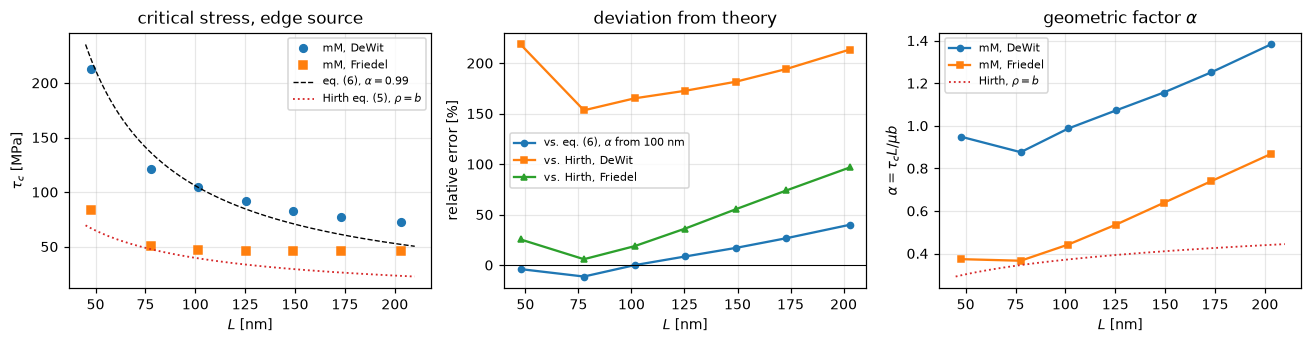

 L [nm]   tau_c  eq.(6)     err   Hirth     err  alpha
   47.7   213.0   221.7   -3.9%    66.9  218.5%   0.95
   77.6   121.1   136.4  -11.3%    47.8  153.3%   0.88
  101.5   104.3   104.3    0.0%    39.3  165.2%   0.99
  125.3    91.7    84.5    8.6%    33.6  172.7%   1.07
  149.2    83.1    70.9   17.1%    29.5  181.6%   1.16
  173.1    77.5    61.2   26.7%    26.3  194.3%   1.25
  202.9    73.0    52.2   40.0%    23.3  213.5%   1.38

scaling exponent: tau_c ~ L^-0.72  (eq. (6): -1; Hirth with ln(L/b): about -0.8)


In [7]:
La, tc, tcf = res_L[:, 1], res_L[:, 2], res_L[:, 3]
tau_eq6 = ALPHA_100 * MU * B / La                       # eq. (6) with alpha from Task 1
tau_h = tau_hirth(90, La)                               # eq. (5), rho = b
alpha_L = tc * La / (MU * B)

fig, ax = plt.subplots(1, 3, figsize=(12.0, 3.2))
Lf = np.linspace(45, 210, 200)
ax[0].plot(La, tc, "o", ms=5, label="mM, DeWit")
ax[0].plot(La, tcf, "s", ms=5, label="mM, Friedel")
ax[0].plot(Lf, ALPHA_100 * MU * B / Lf, "k--", lw=0.9, label=rf"eq. (6), $\alpha = {ALPHA_100:.2f}$")
ax[0].plot(Lf, tau_hirth(90, Lf), "C3:", lw=1.2, label=r"Hirth eq. (5), $\rho = b$")
ax[0].set(xlabel="$L$ [nm]", ylabel=r"$\tau_c$ [MPa]", title="critical stress, edge source")
ax[0].legend(fontsize=7)

ax[1].plot(La, 100 * (tc - tau_eq6) / tau_eq6, "o-", ms=4, label=r"vs. eq. (6), $\alpha$ from 100 nm")
ax[1].plot(La, 100 * (tc - tau_h) / tau_h, "s-", ms=4, label="vs. Hirth, DeWit")
ax[1].plot(La, 100 * (tcf - tau_h) / tau_h, "^-", ms=4, label="vs. Hirth, Friedel")
ax[1].axhline(0, color="k", lw=0.7)
ax[1].set(xlabel="$L$ [nm]", ylabel="relative error [%]", title="deviation from theory")
ax[1].legend(fontsize=7)

ax[2].plot(La, alpha_L, "o-", ms=4, label="mM, DeWit")
ax[2].plot(La, tcf * La / (MU * B), "s-", ms=4, label="mM, Friedel")
ax[2].plot(Lf, alpha_hirth(90, Lf), "C3:", lw=1.2, label=r"Hirth, $\rho = b$")
ax[2].set(xlabel="$L$ [nm]", ylabel=r"$\alpha = \tau_c L/\mu b$", title=r"geometric factor $\alpha$")
ax[2].legend(fontsize=7)
plt.show()

print(f"{'L [nm]':>7s}{'tau_c':>8s}{'eq.(6)':>8s}{'err':>8s}{'Hirth':>8s}{'err':>8s}{'alpha':>7s}")
for i in range(len(La)):
    print(f"{La[i]:7.1f}{tc[i]:8.1f}{tau_eq6[i]:8.1f}{100*(tc[i]-tau_eq6[i])/tau_eq6[i]:7.1f}%"
          f"{tau_h[i]:8.1f}{100*(tc[i]-tau_h[i])/tau_h[i]:7.1f}%{alpha_L[i]:7.2f}")
p = np.polyfit(np.log(La), np.log(tc), 1)[0]
print(f"\nscaling exponent: tau_c ~ L^{p:.2f}  (eq. (6): -1; Hirth with ln(L/b): about -0.8)")

<a id="5"></a>
## 5 Which parameters affect the result (Task 2.6)

In [8]:
param = {}
for L in (50, 200):
    for name, kw in {"reference": {}, "box 1.5 um": dict(box_nm=1500),
                     "ldis 0.1 um": dict(ldis_act=0.1, ldis_nact=0.1),
                     "echelle 10": dict(echelle=10.0)}.items():
        try:
            param[(L, name)] = tau_crit(L, 90, **kw)
        except Exception as exc:                       # some combinations crash mM
            param[(L, name)] = np.nan
            print(f"L={L}, {name}: run failed ({type(exc).__name__})")
for (L, name), v in param.items():
    ref = param[(L, "reference")]
    print(f"L = {L:3d} nm  {name:12s} tau_c = {v:6.1f} MPa  ({100*(v-ref)/ref:+5.1f} %)")

✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


... (32 outputs left out)

✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


L =  50 nm  reference    tau_c =  213.0 MPa  ( +0.0 %)
L =  50 nm  box 1.5 um   tau_c =  213.0 MPa  ( +0.0 %)
L =  50 nm  ldis 0.1 um  tau_c =  155.1 MPa  (-27.2 %)
L =  50 nm  echelle 10   tau_c =  796.0 MPa  (+273.7 %)
L = 200 nm  reference    tau_c =   73.0 MPa  ( +0.0 %)
L = 200 nm  box 1.5 um   tau_c =   73.0 MPa  ( +0.0 %)
L = 200 nm  ldis 0.1 um  tau_c =   70.2 MPa  ( -3.9 %)
L = 200 nm  echelle 10   tau_c =   82.2 MPa  (+12.6 %)


<a id="6"></a>
## 6 Critical stress vs. line orientation (Task 3)

The generator builds a line of character angle $\beta$ as a Bresenham "staircase" of pure edge and
pure screw elementary segments on the $(\bar1\bar1\bar1)$ plane; for $0°$, $60°$ and $90°$ a single
native segment is used. Because the elementary vectors are discrete, the realized angle and length
differ slightly from the targets; we compute $\alpha$ from the realized values.

✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


✅ Generated Native: 90°
✅ Generated Native: 90°


beta = 90 deg (built  90.0 deg, L =  101.5 nm): tau_c =  104.3 MPa, alpha = 0.987


... (42 outputs left out)

✅ Generated Native: 0°


✅ Generated Native: 0°


✅ Generated Native: 0°


beta =  0 deg (built   0.0 deg, L =   99.9 nm): tau_c =  192.9 MPa, alpha = 1.798


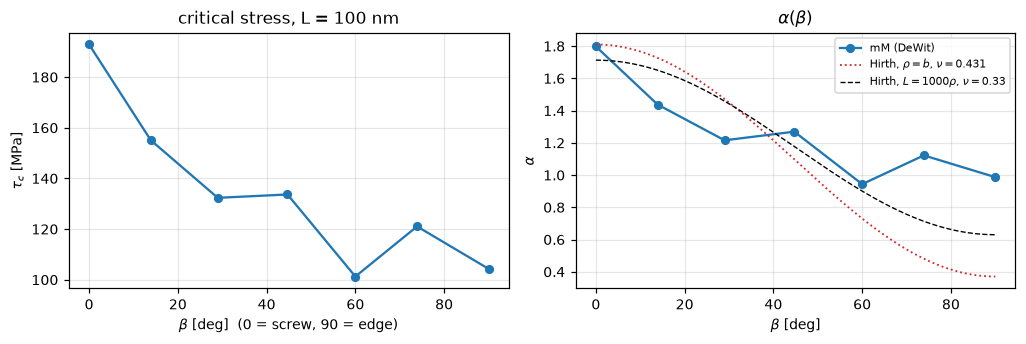

alpha_screw / alpha_edge: mM 1.82, Hirth 4.88


In [9]:
BETAS = [90, 75, 60, 45, 30, 15, 0]
res_b = []
for beta in BETAS:
    La_b, beta_a = actual_geometry(100, beta)
    tc_b = tau_crit(100, beta)
    res_b.append((beta, beta_a, La_b, tc_b, tc_b * La_b / (MU * B)))
    print(f"beta = {beta:2d} deg (built {beta_a:5.1f} deg, L = {La_b:6.1f} nm): "
          f"tau_c = {tc_b:6.1f} MPa, alpha = {res_b[-1][4]:.3f}", flush=True)
res_b = np.array(res_b)

bf = np.linspace(0, 90, 200)
fig, ax = plt.subplots(1, 2, figsize=(9.4, 3.2))
ax[0].plot(res_b[:, 1], res_b[:, 3], "o-", ms=5)
ax[0].set(xlabel=r"$\beta$ [deg]  (0 = screw, 90 = edge)", ylabel=r"$\tau_c$ [MPa]",
          title="critical stress, L = 100 nm")
ax[1].plot(res_b[:, 1], res_b[:, 4], "o-", ms=5, label="mM (DeWit)")
ax[1].plot(bf, alpha_hirth(bf, 100), "C3:", lw=1.2, label=r"Hirth, $\rho = b$, $\nu = 0.431$")
ax[1].plot(bf, alpha_hirth(bf, 100, nu=0.33, L_over_rho=1000), "k--", lw=0.9,
           label=r"Hirth, $L = 1000\rho$, $\nu = 0.33$")
ax[1].set(xlabel=r"$\beta$ [deg]", ylabel=r"$\alpha$", title=r"$\alpha(\beta)$")
ax[1].legend(fontsize=7)
plt.show()
print(f"alpha_screw / alpha_edge: mM {res_b[-1,4]/res_b[0,4]:.2f}, "
      f"Hirth {alpha_hirth(0,100)/alpha_hirth(90,100):.2f}")

## Summary

The numbers printed above are discussed in Part I. In short: the 100 nm edge source operates at
$\tau_c \approx 105$ MPa ($\alpha \approx 1.0$) with the default DeWit line tension, about twice the
Hirth estimate, and at about 47 MPa ($\alpha \approx 0.45$) with Friedel's constant line tension;
$\tau_c$ falls as $L^{-0.72}$ over 50–200 nm, more slowly than $1/L$, so $\alpha$ grows with $L$; box size, step count and re-discretization length hardly
matter, the line-tension model dominates; and $\alpha$ grows as the source turns from edge to screw,
as the orientation-dependent line tension predicts.